In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [13]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [14]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [15]:
crosstab_proportion = pd.crosstab(df['category'], df['isBestSeller'] , normalize='index') 
crosstab_proportion.sort_values(by=True, ascending=False).head(5)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339


Grocery presenta la mayor proporción de productos marcados como best-seller: aproximadamente 5,8 de cada 100 productos de esta categoría. Le siguen muy de cerca Smart Home Security & Lighting y Health & Personal Care. Estos porcentajes describen la presencia de best-sellers dentro de cada categoría, no su volumen de ventas.

In [16]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

# Chi-cuadrado: comprobar si existe asociación
chi2_statistic, p_value, _, expected = chi2_contingency(crosstab_result)

print("Estadístico chi-cuadrado:", chi2_statistic)
print("P-valor:", p_value)

# V de Cramér: medir la fuerza de la asociación
cramers_v = association(crosstab_result, method="cramer")

print("V de Cramér:", cramers_v)

Estadístico chi-cuadrado: 36540.20270061387
P-valor: 0.0
V de Cramér: 0.1222829439760564


In [17]:
print("Frecuencia esperada mínima:", expected.min())
print("Porcentaje de celdas con frecuencia esperada menor que 5:",
      (expected < 5).mean() * 100)

Frecuencia esperada mínima: 0.17634269378074038
Porcentaje de celdas con frecuencia esperada menor que 5: 19.256756756756758


El resultado del chi-cuadrado debe interpretarse con cautela porque algunas frecuencias esperadas son muy bajas. La V de Cramér de 0,122 muestra una asociación débil en los datos. Para confirmar la significación, sería necesario utilizar un método adecuado para frecuencias pequeñas o agrupar categorías con una justificación de negocio.

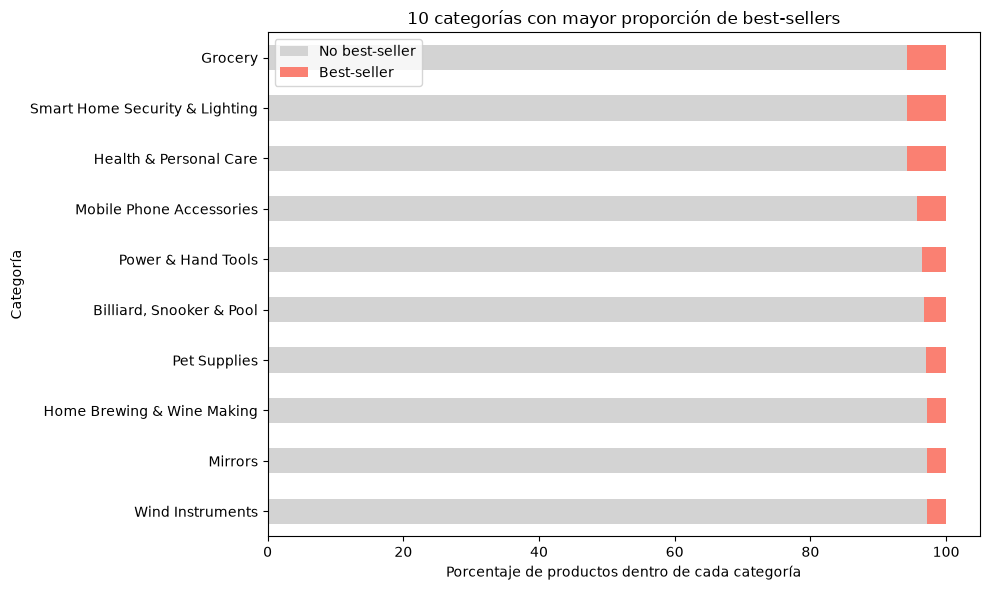

In [18]:
import matplotlib.pyplot as plt

top_10 = crosstab_proportion.sort_values(by=True, ascending=False).head(10)

(top_10 * 100).plot(
    kind='barh',
    stacked=True,
    figsize=(10, 6),
    color=['lightgray', 'salmon']
)

plt.title("10 categorías con mayor proporción de best-sellers")
plt.xlabel("Porcentaje de productos dentro de cada categoría")
plt.ylabel("Categoría")
plt.legend(["No best-seller", "Best-seller"])
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Incluso en las categorías con mayor proporción de best-sellers, estos representan una pequeña parte de los productos: menos del 6 %. Grocery, Smart Home Security & Lighting y Health & Personal Care encabezan la clasificación con porcentajes muy similares, próximos al 5,8 %

In [19]:
# Calcular los cuartiles y el IQR
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

# Establecer los límites
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Conservar los productos con precios dentro de los límites
df_sin_outliers = df.loc[
    (df['price'] >= limite_inferior) &
    (df['price'] <= limite_superior)
].copy()

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Productos originales:", len(df))
print("Productos conservados:", len(df_sin_outliers))
print("Productos excluidos:", len(df) - len(df_sin_outliers))
print(
    "Porcentaje excluido:",
    round((len(df) - len(df_sin_outliers)) / len(df) * 100, 2)
)

Límite inferior: -44.01
Límite superior: 99.99000000000001
Productos originales: 2443651
Productos conservados: 2115963
Productos excluidos: 327688
Porcentaje excluido: 13.41


Aplicando el método IQR, los límites de precio son −44,01 y 99,99. Como los precios del dataset no son negativos, el filtro excluye los productos con precios superiores a 99,99.
Se han excluido 327.688 productos (13,41 %) y se conservan 2.115.963 para continuar el análisis. Estos precios elevados no son necesariamente errores: los excluimos siguiendo el criterio solicitado en el lab.
A partir de ahora, los resultados describen el conjunto filtrado. Esta decisión puede afectar especialmente a las categorías cuyos productos suelen ser más caros.

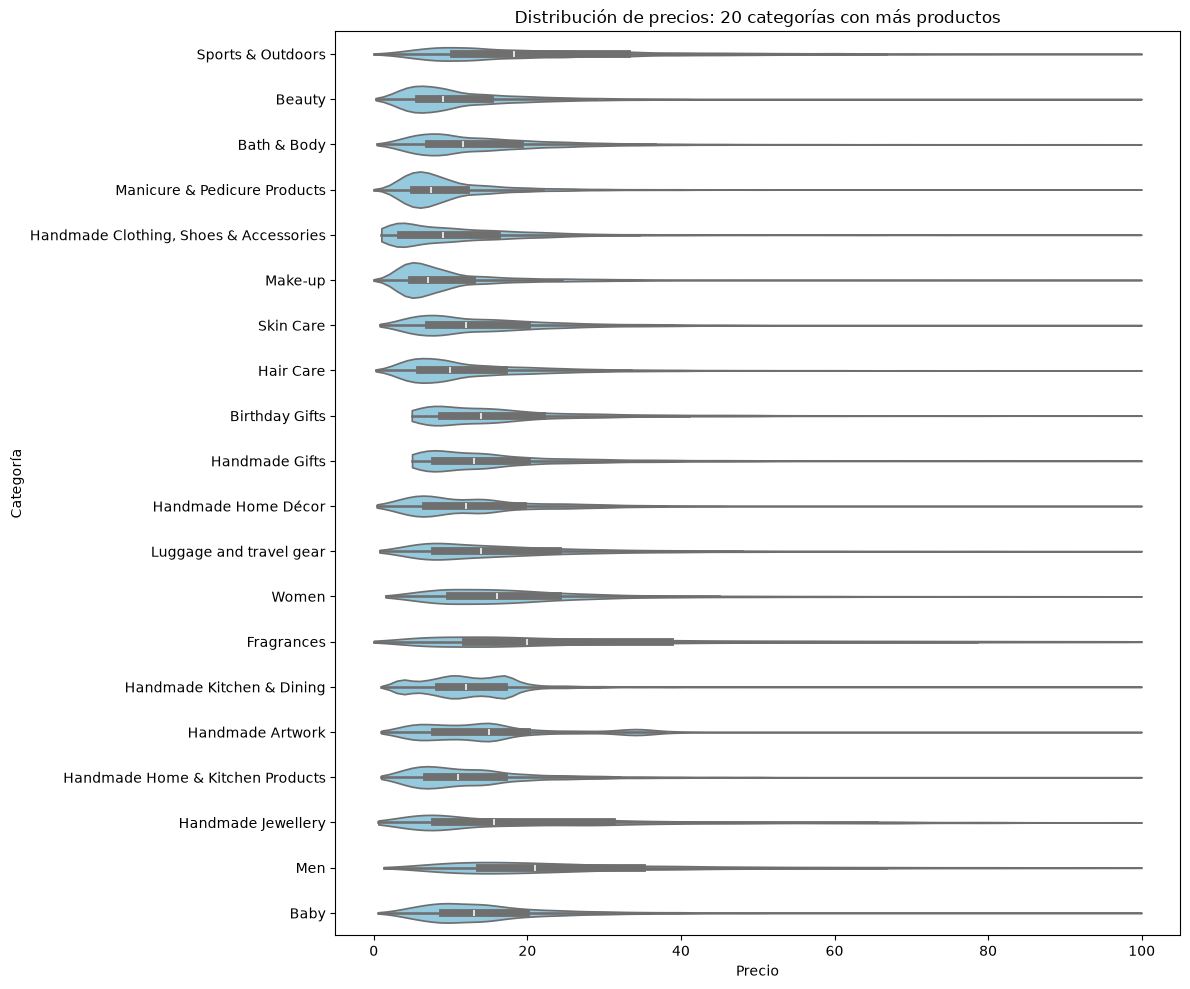

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionar las 20 categorías con más productos tras el filtro
top_20_categorias = df_sin_outliers['category'].value_counts().head(20).index

df_top_20 = df_sin_outliers.loc[
    df_sin_outliers['category'].isin(top_20_categorias)
]

# Distribución de precios por categoría
plt.figure(figsize=(12, 10))

sns.violinplot(
    data=df_top_20,
    x='price',
    y='category',
    order=top_20_categorias,
    color='skyblue',
    cut=0
)

plt.title("Distribución de precios: 20 categorías con más productos")
plt.xlabel("Precio")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

In [21]:
# Comparar las medianas de todas las categorías
medianas_precio = (
    df_sin_outliers.groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

print("Categorías con mayor mediana de precio:")
print(medianas_precio.head(10))

Categorías con mayor mediana de precio:
category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


En las 20 categorías con más productos del conjunto filtrado, los precios suelen concentrarse en la parte baja del intervalo, con colas hacia precios más altos. Categorías como Fragrances y Men muestran precios centrales superiores a los de Beauty o Make-up.
Al comparar todas las categorías, Desktop PCs presenta la mayor mediana de precio (74,00), seguida de Boxing Shoes (69,79) y Tablets (69,00).
Estos resultados corresponden únicamente a los productos conservados tras el filtro IQR, con precios de hasta 99,99. Por tanto, no describen el precio habitual de toda la oferta de estas categorías, especialmente en electrónica.

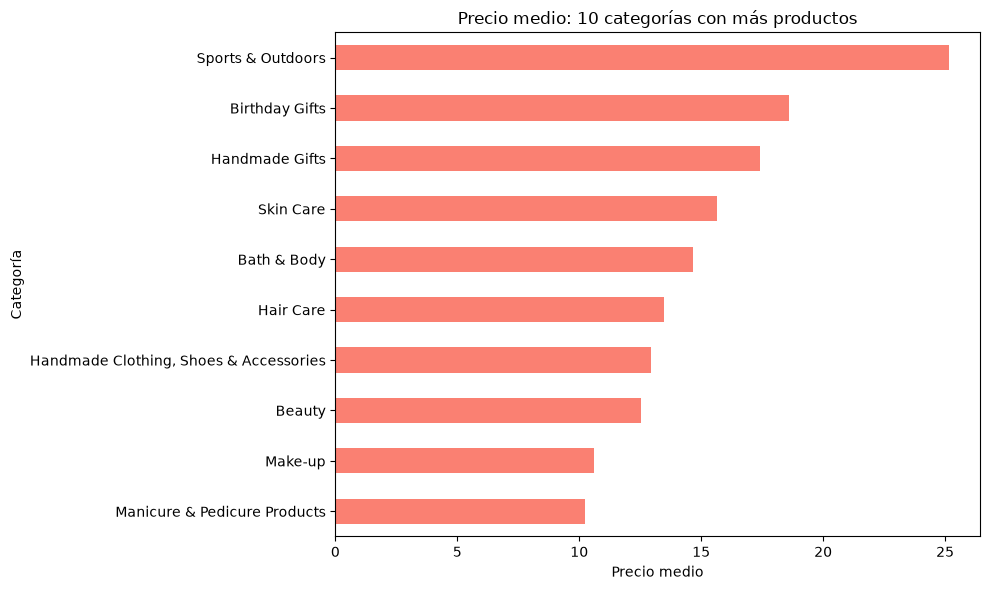

In [22]:
# Seleccionar las 10 categorías con más productos
top_10_categorias = df_sin_outliers['category'].value_counts().head(10).index

# Calcular el precio medio de todas las categorías
medias_precio = df_sin_outliers.groupby('category')['price'].mean()

# Representar las medias de las 10 categorías seleccionadas
medias_precio.loc[top_10_categorias].sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    color='salmon'
)

plt.title("Precio medio: 10 categorías con más productos")
plt.xlabel("Precio medio")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

In [23]:
print("Categorías con mayor precio medio:")
print(medias_precio.sort_values(ascending=False).head(10).round(2))

Categorías con mayor precio medio:
category
Motherboards         68.77
Boxing Shoes         67.42
Desktop PCs          66.92
Tablets              66.55
Graphics Cards       65.10
Digital Frames       60.75
Streaming Clients    60.24
Hockey Shoes         60.09
Computer Cases       58.34
Skiing Poles         57.87
Name: price, dtype: float64


Entre las 10 categorías con más productos del conjunto filtrado, Sports & Outdoors presenta el mayor precio medio, aproximadamente 25, mientras que Manicure & Pedicure Products tiene el menor, alrededor de 10.
Al comparar todas las categorías, Motherboards tiene el precio medio más alto (68,77), seguida de Boxing Shoes (67,42) y Desktop PCs (66,92).
La categoría que lidera en media no coincide con la que lidera en mediana: Desktop PCs tenía la mayor mediana. Ambas medidas describen aspectos diferentes de la distribución.
Estos resultados corresponden a productos con precios de hasta 99,99, tras aplicar el filtro IQR; no representan la oferta completa de cada categoría.

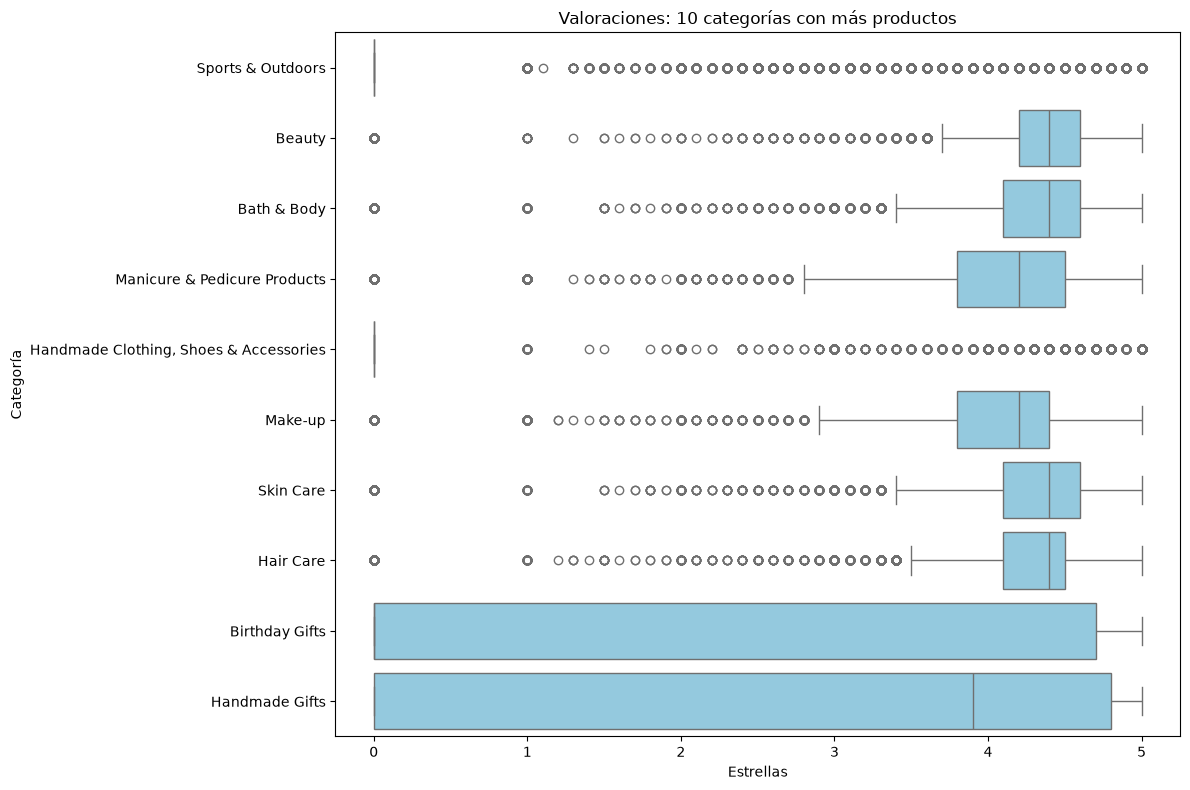

In [24]:
# Seleccionar los productos de las 10 categorías principales
df_top_10 = df_sin_outliers.loc[
    df_sin_outliers['category'].isin(top_10_categorias)
]

plt.figure(figsize=(12, 8))

sns.boxplot(
    data=df_top_10,
    x='stars',
    y='category',
    order=top_10_categorias,
    color='skyblue'
)

plt.title("Valoraciones: 10 categorías con más productos")
plt.xlabel("Estrellas")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

In [25]:
medianas_rating = (
    df_sin_outliers.groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

print("Categorías con mayor mediana de valoración:")
print(medianas_rating.head(10))

# Mostrar todas las categorías empatadas en la primera posición
print("\nCategorías con la mediana máxima:")
print(medianas_rating[medianas_rating == medianas_rating.max()])

Categorías con mayor mediana de valoración:
category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

Categorías con la mediana máxima:
category
Computer Memory    4.7
Name: stars, dtype: float64


In [26]:
medianas_con_valoracion = (
    df_sin_outliers.loc[df_sin_outliers['stars'] > 0]
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

print(medianas_con_valoracion.head(10))

category
Handmade Artwork                          5.0
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Clothing, Shoes & Accessories    4.9
Handmade Kitchen & Dining                 4.9
Birthday Gifts                            4.8
Handmade Home Décor                       4.8
Handmade Gifts                            4.8
Handmade Home & Kitchen Products          4.7
Computer Memory                           4.7
Name: stars, dtype: float64


Entre los productos con puntuación positiva y tras filtrar los precios atípicos, Handmade Artwork, Made in Italy Handmade y Handmade Baby Products alcanzan la mayor mediana: 5 estrellas. Les siguen Handmade Clothing, Shoes & Accessories y Handmade Kitchen & Dining, con 4,9.
Computer Memory mantiene una mediana de 4,7, pero deja de ocupar la primera posición. Esto muestra que incluir los ceros influía en la comparación entre categorías.
Estas medianas describen los productos valorados; para evaluar la solidez de la comparación también habría que considerar cuántos productos y reseñas hay en cada categoría.

In [27]:
# Correlación incluyendo los ceros
correlacion = df_sin_outliers['price'].corr(df_sin_outliers['stars'])

# Seleccionar productos con puntuación positiva
df_valorados = df_sin_outliers.loc[
    df_sin_outliers['stars'] > 0
].copy()

# Correlación entre productos valorados
correlacion_valorados = df_valorados['price'].corr(df_valorados['stars'])

print("Correlación incluyendo ceros:", correlacion)
print("Correlación con puntuación positiva:", correlacion_valorados)

Correlación incluyendo ceros: -0.07767299878178476
Correlación con puntuación positiva: 0.006744508067156739


Tras excluir los precios atípicos y los productos sin valoración, la correlación entre precio y estrellas es prácticamente nula (0,007). En este conjunto, los productos más caros no tienden a recibir valoraciones mayores ni menores de forma lineal. La pequeña correlación negativa observada al incluir ceros cambia al retirar los productos sin reseñas.

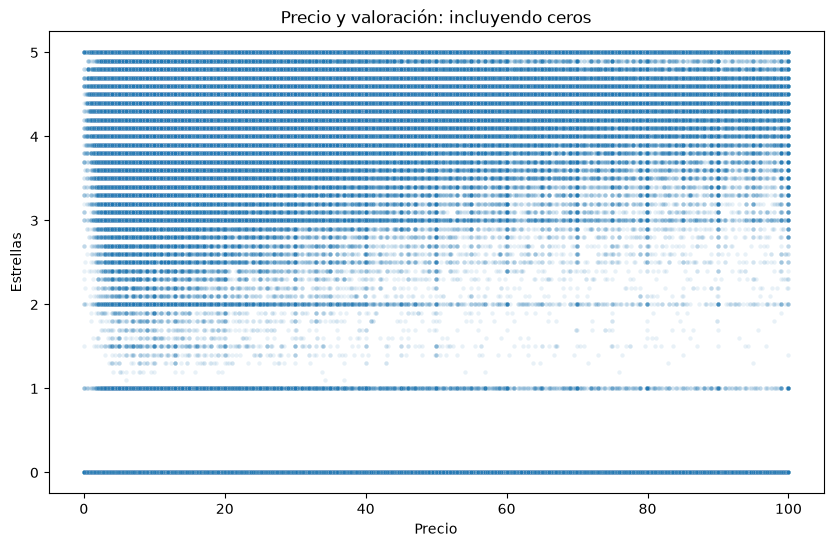

In [28]:
# Incluyendo productos sin valoración
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_sin_outliers,
    x='price',
    y='stars',
    alpha=0.1,
    s=10
)

plt.title("Precio y valoración: incluyendo ceros")
plt.xlabel("Precio")
plt.ylabel("Estrellas")
plt.show()

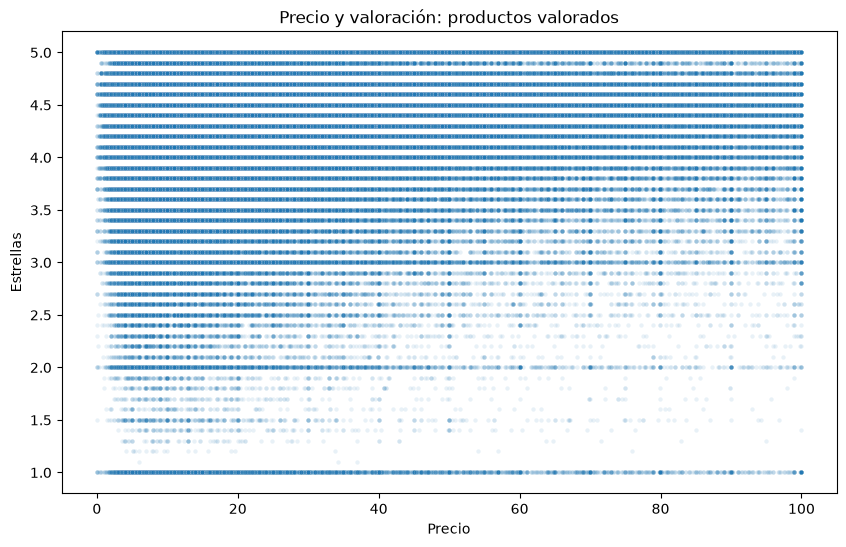

In [29]:
# Solo productos con puntuación positiva
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_valorados,
    x='price',
    y='stars',
    alpha=0.1,
    s=10
)

plt.title("Precio y valoración: productos valorados")
plt.xlabel("Precio")
plt.ylabel("Estrellas")
plt.show()

En los productos con valoración, aparecen puntuaciones altas en todo el intervalo de precios, sin una tendencia ascendente o descendente clara. Esto es coherente con la correlación de Pearson prácticamente nula (0,007).
Al incluir los productos sin reseñas, aparece una banda horizontal en 0 estrellas, que representa ausencia de valoraciones, no opiniones negativas.
Las bandas horizontales se deben a que las puntuaciones toman valores concretos, como 4,1 o 4,2. El gran solapamiento de puntos dificulta comparar visualmente la cantidad de productos en cada zona

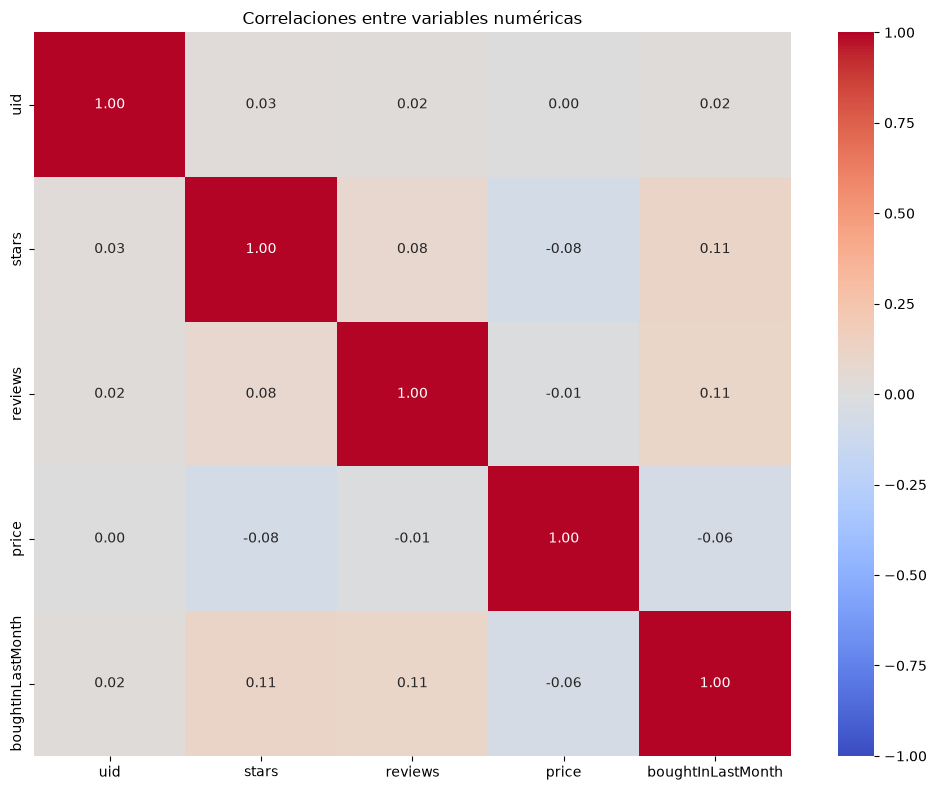

In [30]:
# Seleccionar las columnas numéricas y calcular sus correlaciones
df_numericas = df_sin_outliers.select_dtypes(include='number')
matriz_correlacion = df_numericas.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlaciones entre variables numéricas")
plt.tight_layout()
plt.show()

El mapa de calor muestra correlaciones lineales débiles entre las variables analizadas. Las mayores son de aproximadamente 0,11, entre compras del último mes y valoraciones, y entre compras y número de reseñas.
El precio apenas presenta relación lineal con las reseñas (−0,01) o las compras del último mes (−0,06). Su correlación con las estrellas es −0,08, incluyendo los productos sin valoración. Estas relaciones no demuestran causalidad.

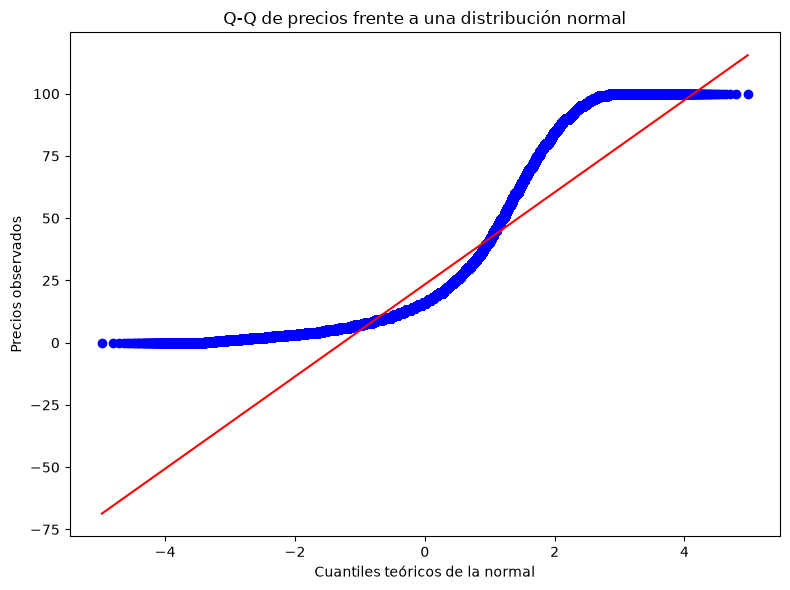

In [31]:
from scipy import stats

plt.figure(figsize=(8, 6))

stats.probplot(
    df_sin_outliers['price'].dropna(),
    dist="norm",
    plot=plt
)

plt.title("Q-Q de precios frente a una distribución normal")
plt.xlabel("Cuantiles teóricos de la normal")
plt.ylabel("Precios observados")
plt.tight_layout()
plt.show()

En el gráfico Q-Q, los puntos se alejan claramente de la recta de referencia, por lo que los precios del conjunto filtrado no presentan una distribución aproximadamente normal.
La curva refleja una concentración en precios bajos y una extensión hacia precios más altos. El aplanamiento superior cerca de 99,99 se debe al límite impuesto por el filtro IQR.
Por tanto, excluir los valores atípicos no ha convertido los precios en una distribución normal.

## Conclusiones finales

### Categorías y best-sellers

Grocery tiene la mayor proporción de best-sellers (5,81 %), seguida de Smart Home Security & Lighting y Health & Personal Care (ambas alrededor del 5,77 %).

La V de Cramér de 0,122 indica una asociación débil entre categoría y condición de best-seller. Aunque el chi-cuadrado devuelve un p-valor muy pequeño, debemos interpretarlo con cautela porque algunas frecuencias esperadas son demasiado bajas.

### Precios por categoría

El filtro IQR excluyó el 13,41 % de los productos, conservando aquellos con precios de hasta 99,99. Estos productos excluidos no son necesariamente errores.

En el conjunto filtrado, Desktop PCs tiene la mayor mediana de precio (74,00), mientras que Motherboards presenta el mayor precio medio (68,77). Estos resultados no representan la oferta completa de cada categoría.

El gráfico Q-Q muestra que los precios siguen sin presentar una distribución aproximadamente normal después del filtro.

### Valoraciones por categoría

Incluir los productos sin reseñas, registrados con 0 estrellas, cambia la comparación entre categorías.

Al considerar únicamente puntuaciones positivas, Handmade Artwork, Made in Italy Handmade y Handmade Baby Products alcanzan una mediana de 5 estrellas. Para valorar la solidez de estos resultados, también habría que revisar cuántos productos y reseñas respaldan cada categoría.

### Relación entre precio y valoración

Entre los productos valorados y sin precios atípicos, la correlación entre precio y estrellas es prácticamente nula (0,007). No encontramos una tendencia lineal que indique que los productos más caros reciben mejores valoraciones.

El mapa de calor tampoco muestra relaciones lineales fuertes entre las variables numéricas con significado de negocio. Esto no descarta otros tipos de relación ni demuestra causalidad.

### Implicaciones para el negocio

- Comparar precios dentro de cada categoría, teniendo en cuenta los productos excluidos por el filtro.
- Evitar utilizar el precio como indicador de satisfacción: los productos más caros no presentan mejores valoraciones de forma lineal.
- Distinguir los productos sin reseñas de los que tienen opiniones de clientes.
- No elegir una categoría comercial solo por su proporción de best-sellers. Conviene incorporar ventas, competencia, costes y márgenes antes de tomar decisiones.